# Prédire le défaut de crédit, puis calculer les pertes attendues IFRS 9

Ce carnet raconte le projet en cellules courtes. Le calcul complet est dans `scripts/`,
le rapport dans `report/main.pdf`. Tous les chiffres viennent des fichiers `results/*.json`
produits par `python run_all.py`.

**Les données** : 620 779 prêts réels de Lending Club (prêts à la consommation américains,
36 mois, émis de 2007 à 2015, tous terminés : remboursés ou passés en perte).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display
from src import config
from src.data import load_loans, modelling_sample, time_split

R = lambda name: json.load(open(ROOT / "results" / f"{name}.json"))
fig = lambda name: display(Image(filename=str(ROOT / "figures" / f"{name}.png"), width=750))

## 1. Les données et la découpe dans le temps

Un prêt est « en défaut » s'il a été passé en perte (*charged off*).
On découpe **dans le temps**, comme en vrai : on apprend sur le passé, on teste sur le futur.
- entraînement : prêts émis de 2007 à 2014 ;
- validation : janvier à juin 2015 (pour régler et calibrer) ;
- test : juillet à décembre 2015 (touché une seule fois, à la fin).

In [2]:
loans = modelling_sample(load_loans())
train, valid, test = time_split(loans)
for name, d in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:6s} {len(d):>8,} prêts   taux de défaut {d['default'].mean():.1%}")

train   337,992 prêts   taux de défaut 13.2%
valid   120,790 prêts   taux de défaut 15.1%
test    161,997 prêts   taux de défaut 14.7%


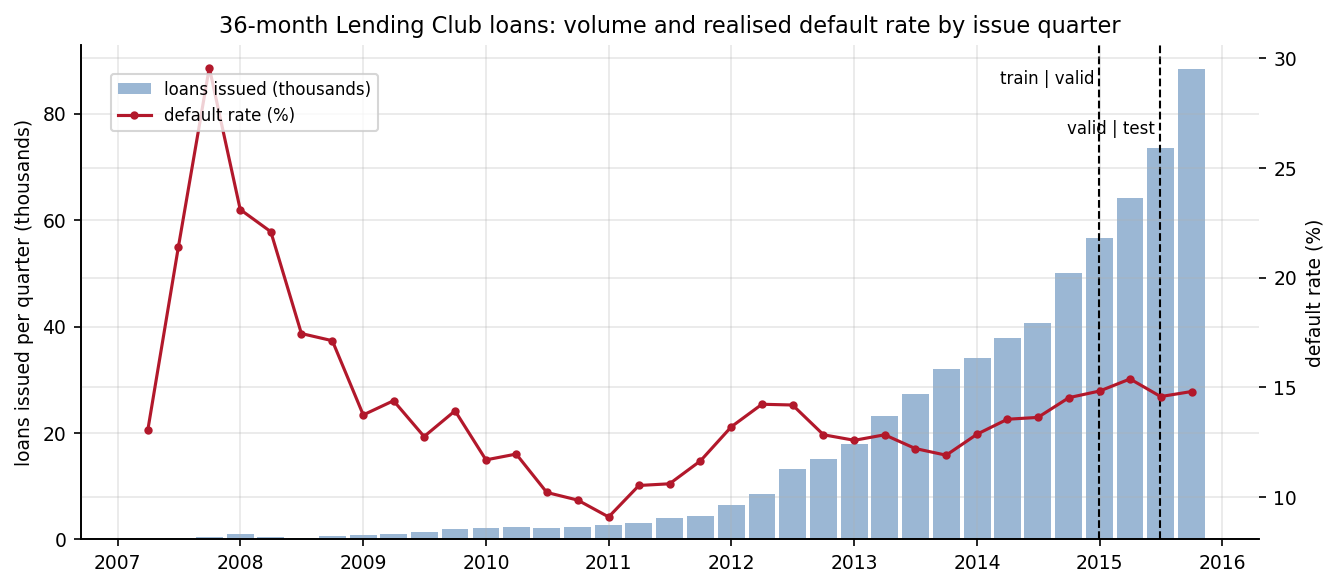

In [3]:
fig("fig01_volume_default_rate")

Le taux de défaut monte avec le temps (13 % en entraînement, 15 % en 2015) :
Lending Club a prêté à des clients plus risqués. C'est pour ça qu'il faudra **recalibrer**
les probabilités sur la période la plus récente (partie 5).

## 2. La carte de score classique : WoE et IV

On coupe chaque variable en tranches. Pour chaque tranche :
- **WoE** = ln(part des bons clients / part des mauvais). Positif = tranche plus sûre ;
- **IV** (information value) = force de la variable. On garde les variables avec IV ≥ 0,02.

Puis une régression logistique sur les WoE donne des **points** : +20 points = risque divisé par 2.

In [4]:
sc = R("scorecard")
pd.Series(sc["iv"]).round(3).head(10)

fico                0.139
annual_inc          0.083
dti                 0.044
loan_to_income      0.042
mort_acc            0.035
home_ownership      0.035
revol_util          0.025
purpose             0.025
inq_last_6mths      0.024
credit_age_years    0.019
dtype: float64

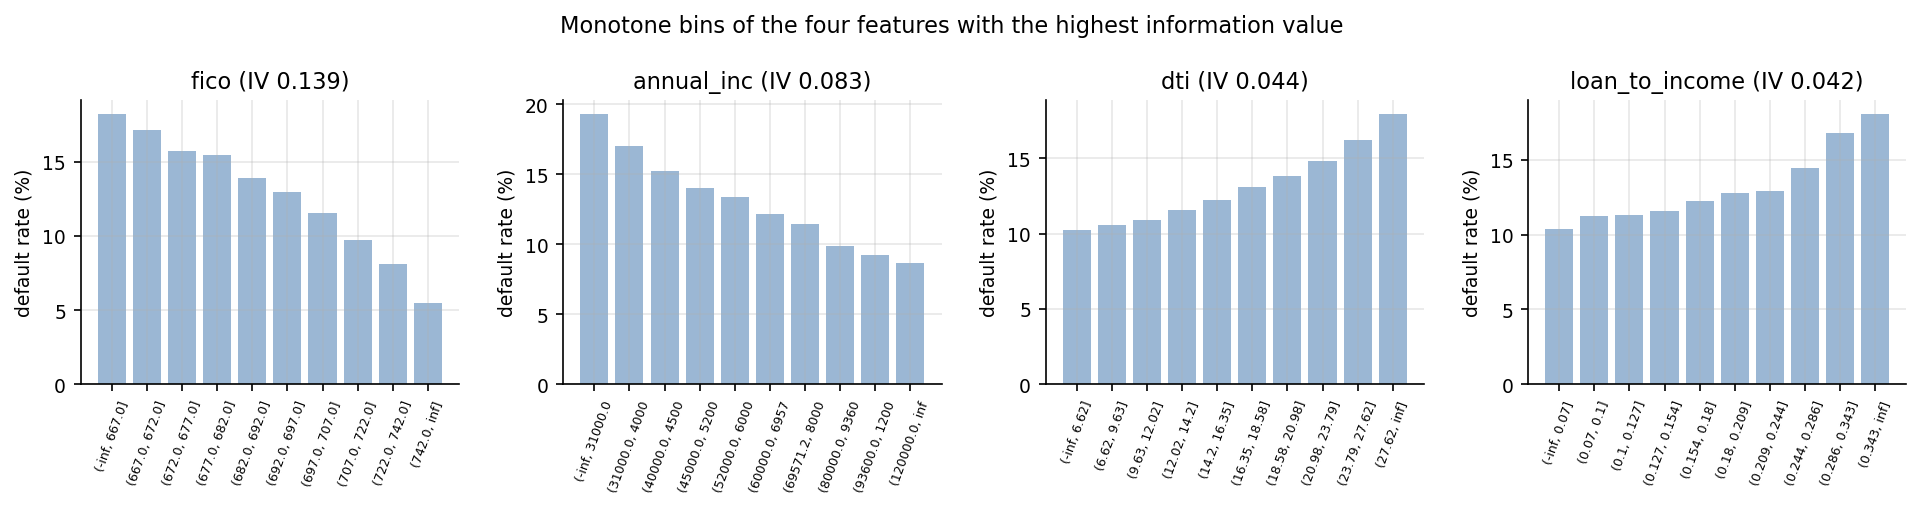

In [5]:
fig("fig04_woe_bins")

In [6]:
pts = pd.read_csv(ROOT / "results" / "scorecard_points.csv")
pts[pts.feature == "fico"].round(1)

,feature,bin,woe,points
0,fico,"(-inf, 667.0]",-0.4,50.6
1,fico,"(667.0, 672.0]",-0.3,52.4
2,fico,"(672.0, 677.0]",-0.2,55.0
3,fico,"(677.0, 682.0]",-0.2,55.5
4,fico,"(682.0, 692.0]",-0.1,58.6
5,fico,"(692.0, 697.0]",0.0,60.6
6,fico,"(697.0, 707.0]",0.1,63.8
7,fico,"(707.0, 722.0]",0.3,68.7
8,fico,"(722.0, 742.0]",0.5,73.6
9,fico,"(742.0, inf]",1.0,84.2


Le score FICO est de loin la variable la plus forte. Résultat de la carte de score sur le test :

In [7]:
print("carte de score   AUC", round(sc["test"]["auc"], 3), " Gini", round(sc["test"]["gini"], 3))
print("sous-note Lending Club AUC", round(sc["lc_subgrade_test"]["auc"], 3), "(référence : LC a plus d'informations)")

carte de score   AUC 0.65  Gini 0.3
sous-note Lending Club AUC 0.681 (référence : LC a plus d'informations)


## 3. Comparer 8 modèles

Réglage des hyperparamètres : recherche aléatoire, validation croisée **mélangée** à 5 plis,
sur 60 000 prêts d'entraînement. Puis chaque modèle est réentraîné sur tout l'entraînement.

Mesures sur le test, avec un intervalle à 95 % par **bootstrap** (on retire 300 fois les prêts au hasard) :
- **AUC** : probabilité qu'un mauvais client ait un score plus risqué qu'un bon ;
- **Gini** = 2 × AUC − 1 (la mesure des banques) ;
- **KS** : plus grand écart entre les deux distributions de score ;
- **Brier** : erreur quadratique de la probabilité (plus bas = mieux) ;
- **PR-AUC** : aire sous la courbe précision-rappel (utile car les défauts sont rares).

In [8]:
m = R("models")
rows = {k: {mm: v["test"][mm]["value"] for mm in ["auc", "gini", "ks", "brier", "pr_auc"]}
        for k, v in m["results"].items()}
table = pd.DataFrame(rows).T.sort_values("auc", ascending=False).round(4)
table

,auc,gini,ks,brier,pr_auc
lightgbm,0.6733,0.3466,0.2498,0.1198,0.2501
vote,0.6724,0.3449,0.2490,0.1198,0.2498
mlp,0.6721,0.3442,0.2489,0.1196,0.2501
hist_gb,0.6688,0.3377,0.2427,0.1202,0.2467
random_forest,0.6678,0.3356,0.2435,0.1204,0.2439
logistic,0.6611,0.3223,0.2308,0.1206,0.2385
scorecard,0.6501,0.3003,0.2166,0.1213,0.2315
tree,0.6407,0.2814,0.2007,0.1219,0.2185


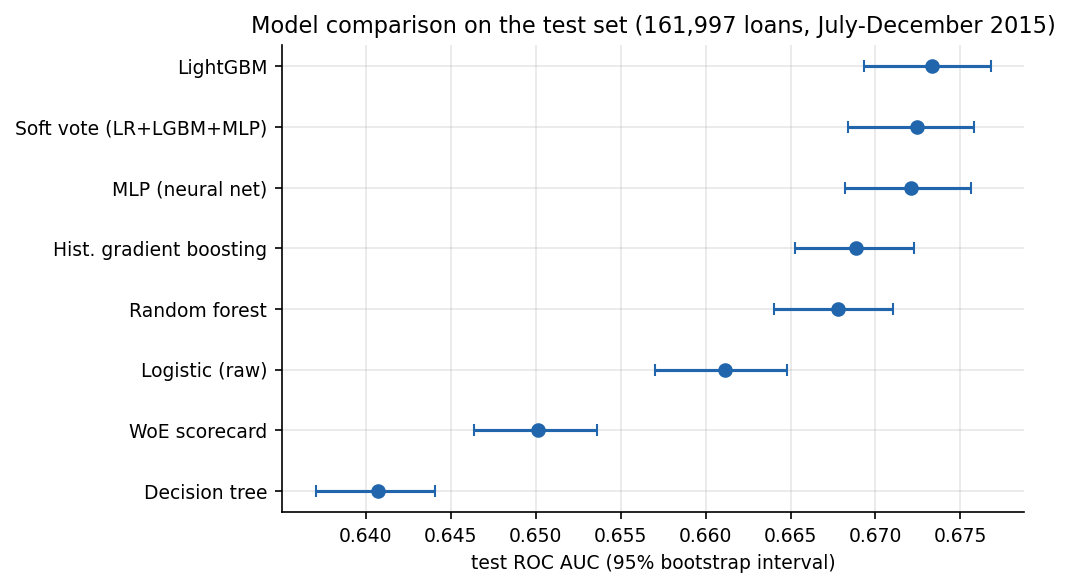

In [9]:
fig("fig05_model_auc")

In [10]:
d = m["lightgbm_minus_scorecard_auc"]
print(f"LightGBM - carte de score : {d['diff']:+.4f} AUC  (IC 95 % : {d['low']:+.4f} à {d['high']:+.4f})")

LightGBM - carte de score : +0.0232 AUC  (IC 95 % : +0.0213 à +0.0248)


Le gain du boosting sur la carte de score est réel (l'intervalle ne contient pas 0) mais
modeste : avec ces variables, la limite vient surtout de l'information disponible, pas du modèle.

## 4. Courbes d'apprentissage

Est-ce que plus de données aideraient ? On entraîne sur 2 000 à 338 000 prêts et on mesure l'AUC en validation.

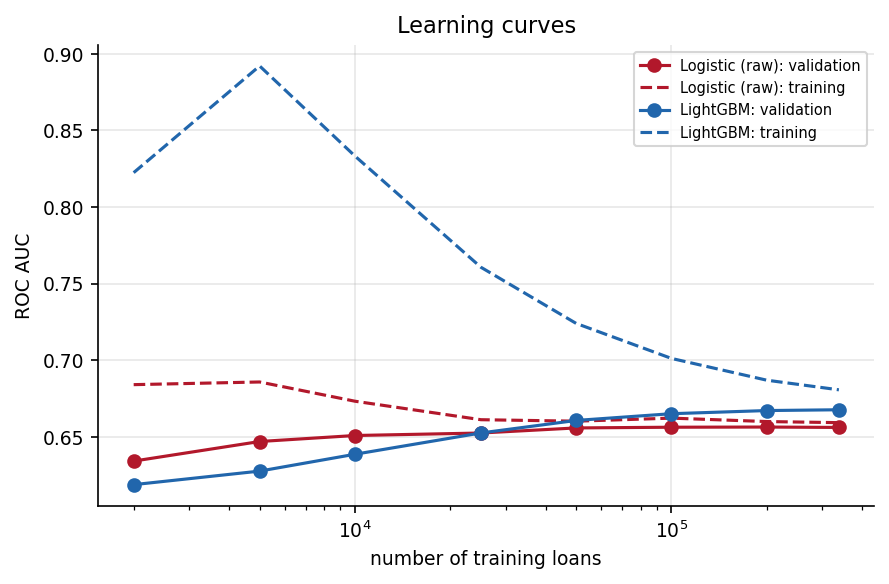

In [11]:
fig("fig07_learning_curves")

## 5. Calibration : une PD doit être une vraie probabilité

Pour IFRS 9 et le prix du crédit, il ne suffit pas de bien classer : si le modèle dit 10 %,
il faut ~10 % de défauts. On recalibre sur la validation avec **Platt** (logistique sur le score)
et **isotonique** (fonction en escalier croissante), et on choisit la méthode par validation croisée.

In [12]:
c = R("calibration")
print("modèle champion :", c["champion"], " | méthode retenue :", c["chosen_method"])
pd.DataFrame(c["test"]).T[["auc", "brier", "ece", "mean_pd"]].round(4)

modèle champion : mlp  | méthode retenue : isotonic


,auc,brier,ece,mean_pd
raw,0.6721,0.1196,0.0113,0.1357
platt,0.6721,0.1195,0.0018,0.1467
isotonic,0.6717,0.1196,0.0034,0.1467


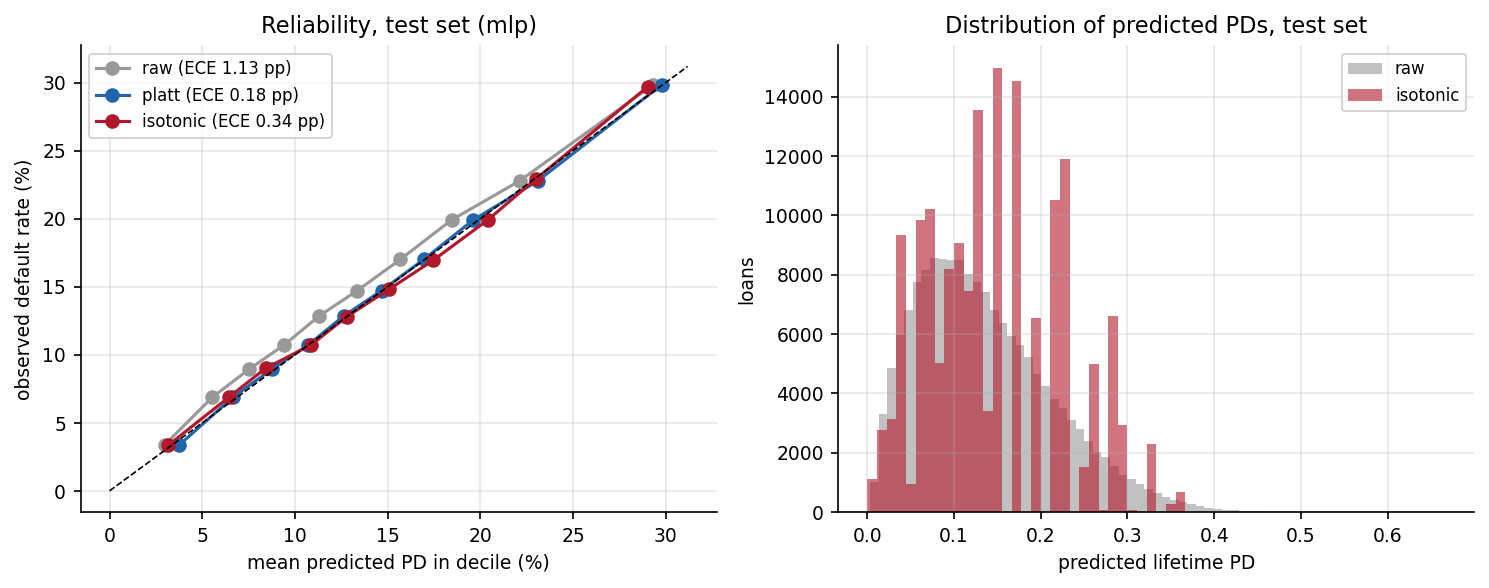

In [13]:
fig("fig08_calibration")

## 6. Expliquer les prédictions avec SHAP

SHAP découpe chaque prédiction en contributions de chaque variable (en log-odds).
La somme des contributions + la moyenne = la prédiction, exactement.
On explique LightGBM (SHAP exact et rapide pour les arbres) : son AUC est presque celle du MLP champion.

In [14]:
s = R("shap")
print("erreur d'additivité max :", s["additivity_max_error"])
pd.Series(s["mean_abs_shap_grouped"]).head(8).round(4)

erreur d'additivité max : 1.2878587085651816e-14


fico              0.3029
annual_inc        0.1419
purpose           0.1350
inq_last_6mths    0.1293
dti               0.1225
loan_to_income    0.1134
revol_bal         0.0769
home_ownership    0.0738
dtype: float64

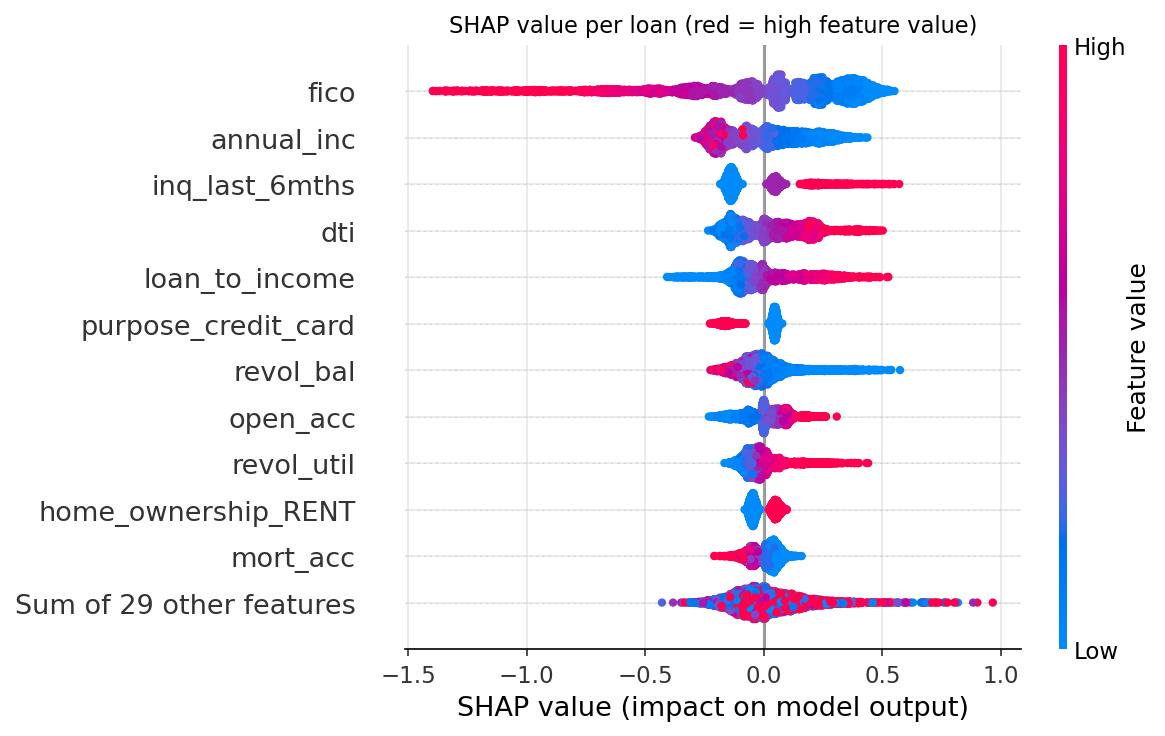

In [15]:
fig("fig10_shap_beeswarm")

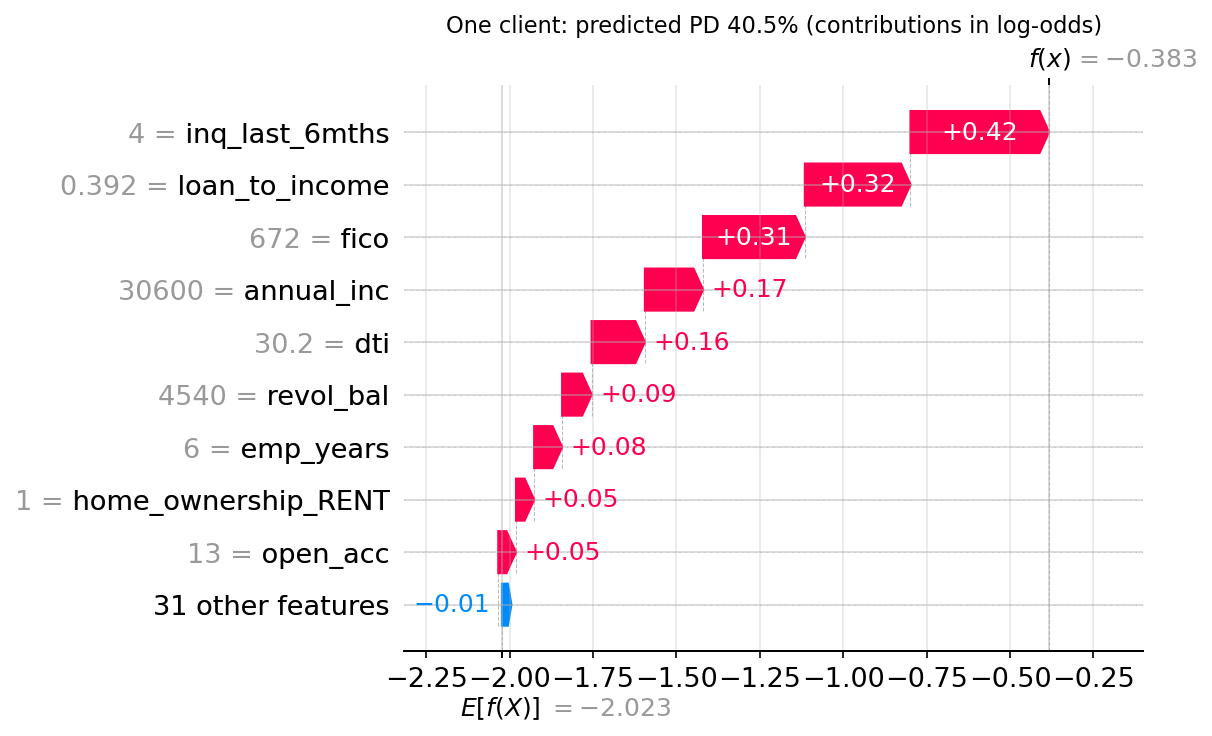

In [16]:
fig("fig11_shap_waterfall")

## 7. Stabilité et sous-groupes

**PSI** (population stability index) : la population qui arrive ressemble-t-elle à celle
de l'entraînement ? < 0,10 stable ; 0,10–0,25 à surveiller ; > 0,25 changement important.

In [17]:
st = R("stability")
print("PSI du score, train vs test :", round(st["psi_score"]["train_vs_test"], 3))
pd.DataFrame(st["psi_by_quarter"]).T.round(3).head(12)

PSI du score, train vs test : 0.001


,n,psi,mean_raw_pd
2016Q1,94592.0,0.004,0.135
2016Q2,73666.0,0.001,0.137
2016Q3,73579.0,0.005,0.138
2016Q4,76440.0,0.003,0.133
2017Q1,69778.0,0.009,0.129
2017Q2,73380.0,0.012,0.128
2017Q3,80528.0,0.012,0.128
2017Q4,72798.0,0.042,0.121
2018Q1,65848.0,0.057,0.119
2018Q2,81015.0,0.043,0.121


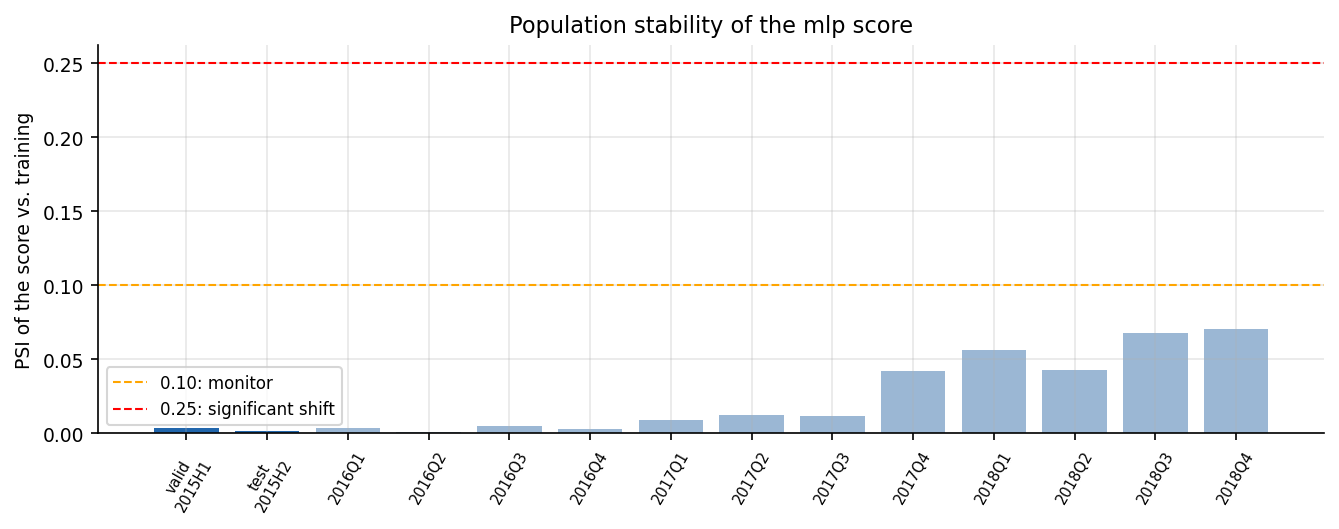

In [18]:
fig("fig12_psi")

In [19]:
pd.DataFrame(st["groups"]["income_quintile"]).round(3)

,group,n,observed_dr,predicted_pd,auc
0,Q1 (lowest),33835,0.193,0.203,0.633
1,Q2,33136,0.160,0.163,0.650
2,Q3,31367,0.145,0.141,0.662
3,Q4,33741,0.128,0.122,0.676
4,Q5 (highest),29918,0.105,0.100,0.690


## 8. IFRS 9 : de la PD à la perte attendue (ECL)

Portefeuille : les prêts du test, vus au **30 juin 2016**.
- **Stage 1** : pas de dégradation → perte attendue sur **12 mois** ;
- **Stage 2** : dégradation significative (30 jours de retard, ou PD annualisée ×2) → perte sur **toute la durée restante** ;
- **Stage 3** : en défaut (> 90 jours de retard) → PD = 100 %.

ECL = somme sur les mois de PD marginale × LGD × EAD × actualisation.
La LGD vient des récupérations réelles sur les prêts en perte ; l'EAD du tableau d'amortissement.

In [20]:
e = R("ifrs9")
print(f"LGD (pondérée par l'EAD) : {e['lgd_ead_weighted']:.1%}")
print(f"part des défauts dans les 12 premiers mois : {e['timing_share_first_12m']:.1%}")
pd.DataFrame(e["stages"]).T.round(3)

LGD (pondérée par l'EAD) : 89.2%
part des défauts dans les 12 premiers mois : 31.3%


,n,ead,ecl,coverage
1,145979.0,1.493423e+09,6.637295e+07,0.044
2,1375.0,1.367808e+07,1.111298e+06,0.081
3,937.0,8.905735e+06,7.943558e+06,0.892


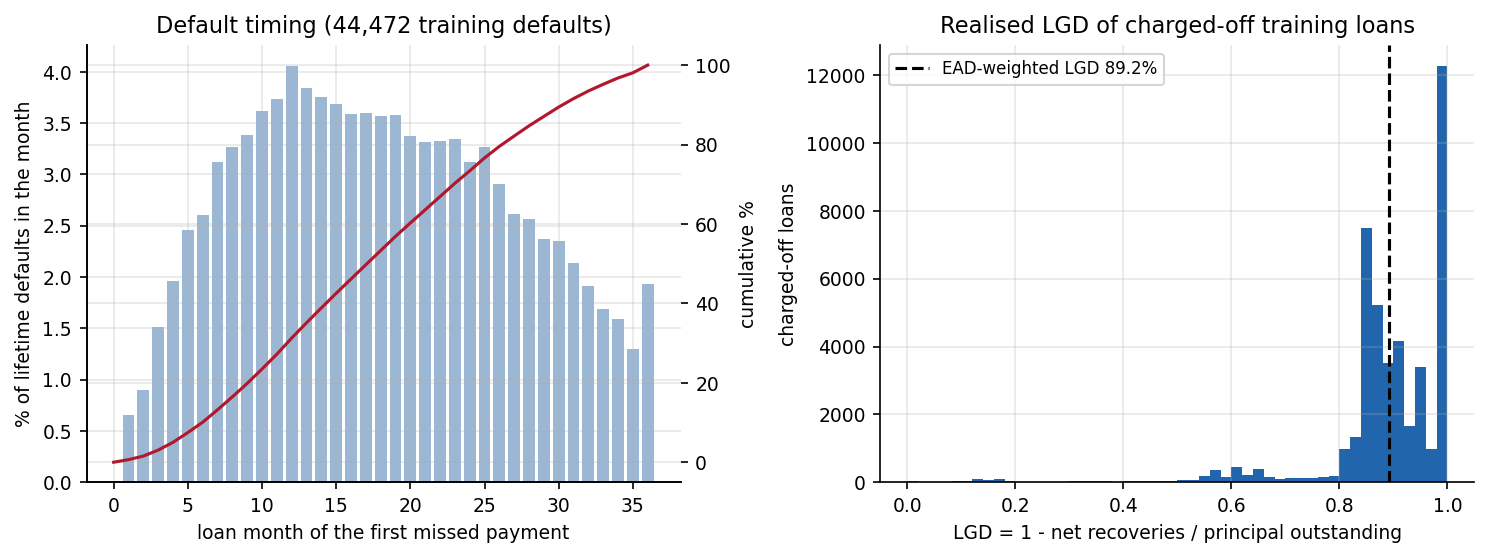

In [21]:
fig("fig14_timing_lgd")

Trois scénarios macroéconomiques : le chômage américain baisse de 1 point, reste stable,
ou monte de 3 points. Le lien chômage → défaut est estimé sur les données FRED (taux de
pertes des banques sur les crédits à la consommation depuis 1985).

In [22]:
pd.DataFrame(e["scenarios"]).T.round(2)

,weight,delta_unemployment,unemployment,ecl
upside,0.15,-1.0,3.9,69627866.72
base,0.60,0.0,4.9,73100153.47
downside,0.25,3.0,7.9,84494151.40


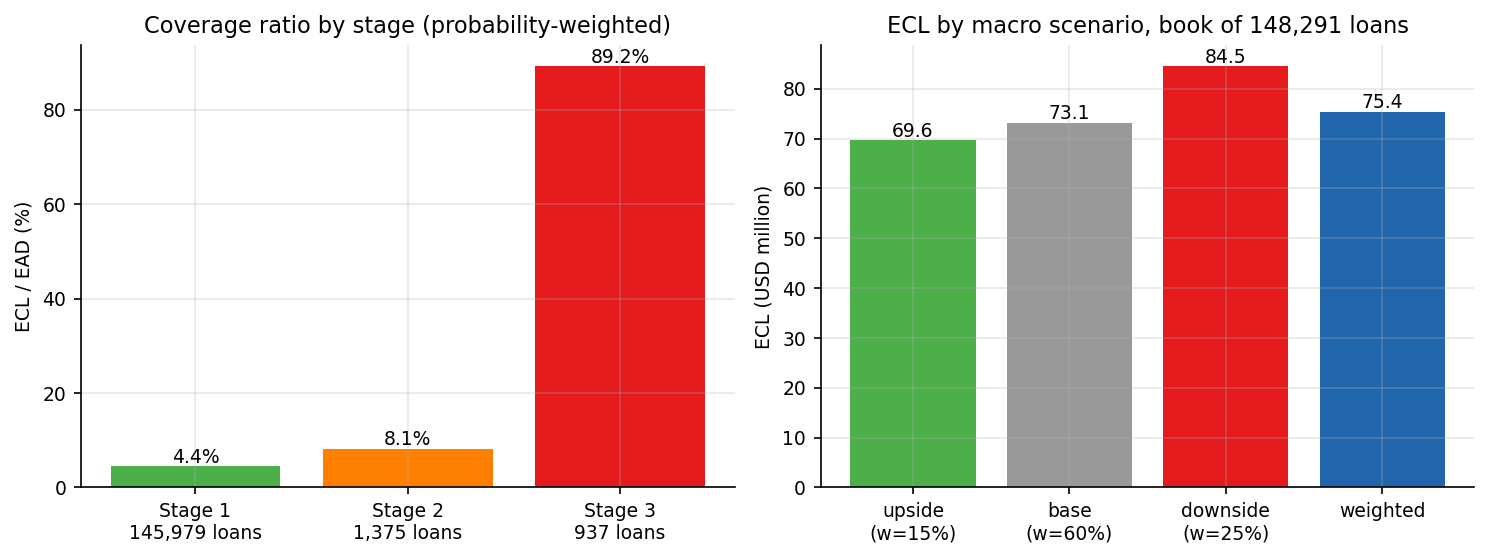

In [23]:
fig("fig16_ecl")

In [24]:
bt = e["backtest"]
print(f"défauts prédits après le 30-06-2016 : {bt['predicted_remaining_lifetime_pd']:.1%}")
print(f"défauts réalisés                     : {bt['realised_default_rate']:.1%}")
print(f"perte prédite (base, durée de vie)   : {bt['predicted_lifetime_loss_undiscounted_base']/1e6:.1f} M USD")
print(f"perte réalisée                       : {bt['realised_principal_loss']/1e6:.1f} M USD")

défauts prédits après le 30-06-2016 : 12.4%
défauts réalisés                     : 13.4%
perte prédite (base, durée de vie)   : 96.6 M USD
perte réalisée                       : 115.4 M USD


## 9. Le seuil d'octroi

Refuser un bon client coûte sa marge ; accepter un mauvais client coûte sa perte.
Les deux coûts sont mesurés sur les prêts réels de l'entraînement. Le seuil optimal théorique
(Bayes) est PD* = coût du refus / (coût du refus + coût du défaut).

In [25]:
t = R("threshold")
print(f"coût d'un bon client refusé : {t['c_fp_refuse_good']:.1%} du montant")
print(f"coût d'un défaut accepté    : {t['c_fn_accept_bad']:.1%} du montant")
print(f"seuil de Bayes : {t['bayes_cutoff']:.1%}   seuil qui maximise le profit (validation) : {t['profit_max_cutoff_valid']:.1%}")
pd.DataFrame(t["test"]).T.round(3)

coût d'un bon client refusé : 16.5% du montant
coût d'un défaut accepté    : 35.9% du montant
seuil de Bayes : 31.5%   seuil qui maximise le profit (validation) : 35.5%


,cutoff,approval_rate,default_rate_approved,default_rate_refused,good_refused_share,bad_caught_share,profit_usd,profit_per_dollar_lent
approve_all,1.010,1.000,0.147,NaN,0.000,0.000,1.318341e+08,0.063
bayes_cutoff,0.315,0.980,0.142,0.375,0.015,0.052,1.329736e+08,0.065
cost_min_on_valid,0.310,0.980,0.142,0.375,0.015,0.052,1.329736e+08,0.065
profit_max_on_valid,0.355,0.996,0.146,0.409,0.003,0.012,1.321800e+08,0.064


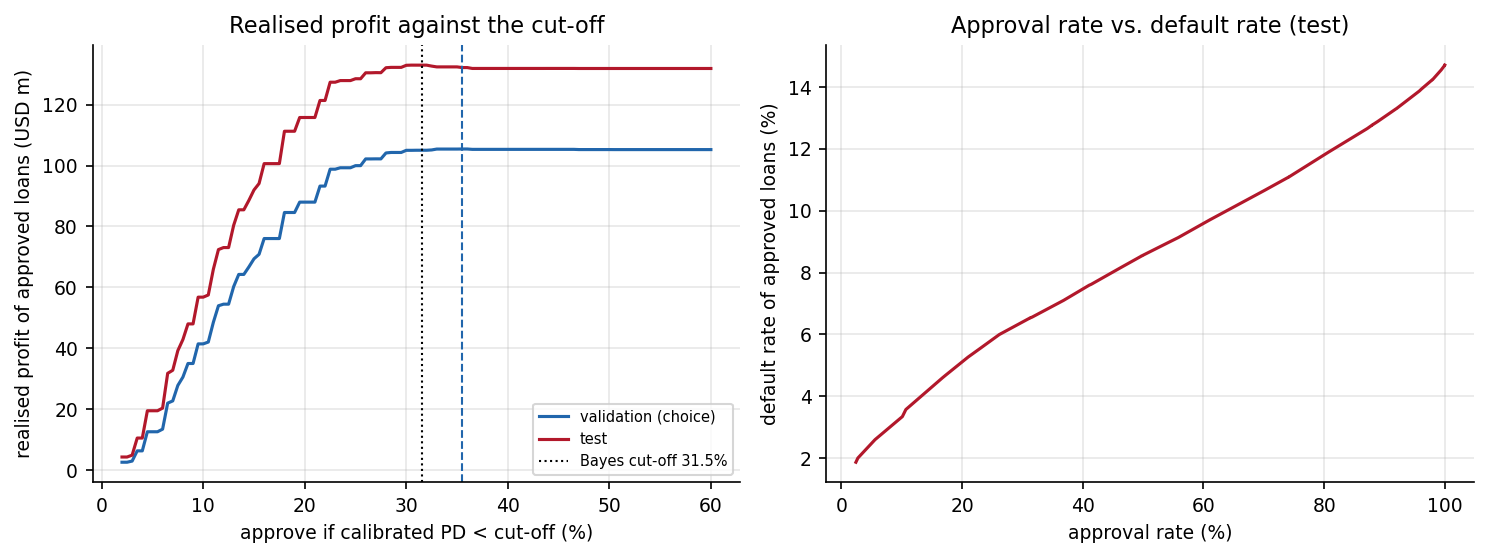

In [26]:
fig("fig17_threshold")

## Limites (à dire franchement)
- Lending Club n'est pas une banque suisse : prêts non garantis américains, 2007–2015.
- La date de défaut et les retards au 30-06-2016 sont reconstruits à partir de la date du dernier paiement.
- Pas de nouvelle note de crédit mensuelle : le test de dégradation (SICR) est simplifié.
- Les poids et les chocs des scénarios sont des hypothèses ; le lien macro vient d'un autre portefeuille (banques US).
- Pas d'âge ni de sexe dans les données : l'équité est vérifiée par segment, pas sur des attributs protégés.